# V01: Amazon S3 through customer egress

Read a small private S3 object from an AIDP workspace through your approved outbound network path.

[Choose another use case](README.md). This notebook is an unexecuted sample, not a live validation report.


## Network setup

Complete and verify these prerequisites with your network/service administrator before the workload comparison. The notebook does not create routes, change policies, configure DNS, or start compute.

| Area | Required setup and verification |
| --- | --- |
| Workspace | Enable private network access and select the customer VCN, subnet and applicable NSGs. Confirm the service-required IAM and network prerequisites in the AIDP workspace documentation. |
| Route | For the illustrated IPv4 NAT design, the customer subnet has a default route to an existing NAT gateway. Use your approved equivalent egress path if different. This example uses the S3 public regional endpoint, not a private OCI-to-AWS interconnect. |
| DNS | Copy the actual regional and bucket-specific hostnames used by your S3 client. Add the required exact destinations in advanced DNS when appropriate. Include redirect destinations observed by the client; do not use a broad domain wildcard. |
| Security | Permit outbound HTTPS to the chosen S3 endpoint through subnet rules, NSGs and any firewall; allow return traffic for the connection. No unsolicited inbound internet rule or AWS VPC is required for this example. |
| Service and fixture | Use an existing private bucket with a known CSV object no larger than 64 KiB. Configure a supported S3A credential provider and runtime-matched Hadoop/AWS libraries before the comparison; do not embed access keys or change libraries during the test. |


### Example network topology

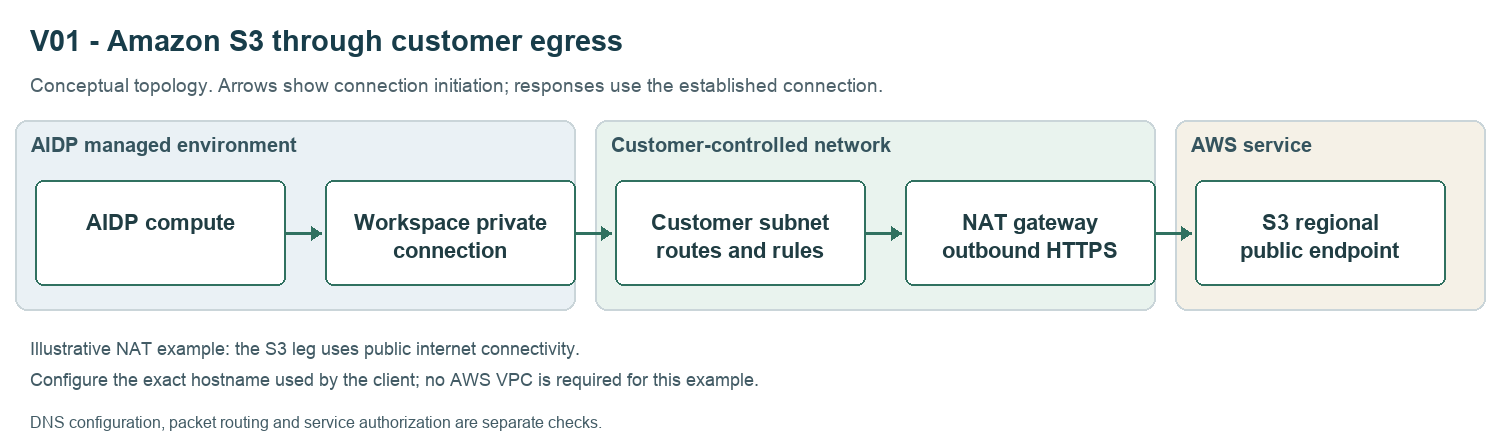

The diagram is illustrative; it does not prove the route taken by a request.


## Test procedure

1. Record baseline saved DNS/SCAN settings and the actual S3 client endpoint.
2. Run the baseline fixture read with the same runtime identity you will use afterward.
3. If the destination needs advanced DNS, add only its exact FQDN through Workbench; capture the operation result and reopened saved configuration.
4. Rerun the same reader and compare exact rows. Restore only the entries added for this test.

**Acceptance:** The authenticated S3 read returns the expected rows. Configuration, DNS and optional TCP results are separate. Review route evidence before claiming a specific outbound path.


## Test helpers

Run once to define this case's checks. Definitions make no network calls. AIDP uses Spark for the data-operation cells; no separate helper file is required.


In [ ]:
CASE_NAMES = {'V01': 'Amazon S3 through customer egress'}

import argparse
import collections
import datetime
import hashlib
import json
import socket
import time
from pathlib import Path
from urllib.parse import urlsplit

class Prerequisite(Exception):
    pass

def utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'))

def same(a, b):
    return canonical(a) == canonical(b)

def zone_match(host, zone):
    host, zone = (host.lower().rstrip('.'), zone.lower().rstrip('.'))
    return host == zone or host.endswith('.' + zone)

def endpoint_host(value):
    return urlsplit(value if '://' in value else 'https://' + value).hostname

def fixture_read(spark, cfg):
    """Bounded CSV check; connector options apply to this reader, not globally."""
    for key in ('uri', 'endpoint', 'expected_rows'):
        if not cfg.get(key):
            raise Prerequisite('Missing fixture ' + key)
    uri, endpoint = (cfg['uri'], cfg['endpoint'])
    if '?' in uri or '#' in uri or '?' in endpoint or ('#' in endpoint):
        raise Prerequisite('Use unsigned fixture and endpoint references')
    parsed_endpoint = urlsplit(endpoint if '://' in endpoint else 'https://' + endpoint)
    if parsed_endpoint.username is not None or parsed_endpoint.password is not None:
        raise Prerequisite('Endpoint must not contain embedded credentials')
    if not parsed_endpoint.hostname:
        raise Prerequisite('Missing endpoint hostname')
    if uri.startswith('s3a://') and '@' in uri.split('://', 1)[1].split('/', 1)[0]:
        raise Prerequisite('S3 URI must not contain embedded credentials')
    expected = cfg['expected_rows']
    if not isinstance(expected, list) or not 1 <= len(expected) <= 100:
        raise Prerequisite('Supply 1 to 100 expected synthetic CSV rows')
    size = cfg.get('fixture_size_bytes')
    if not isinstance(size, int) or isinstance(size, bool) or (not 0 < size <= 65536):
        raise Prerequisite('Verify fixture size is between 1 byte and 64 KiB')
    reader = spark.read.option('header', 'true').option('inferSchema', 'false')
    if uri.startswith('s3a://'):
        if not cfg.get('region'):
            raise Prerequisite('Missing AWS region')
        reader = reader.option('fs.s3a.endpoint', endpoint).option('fs.s3a.endpoint.region', cfg['region'])
    elif uri.startswith('oci://'):
        authority = uri.split('://', 1)[1].split('/', 1)[0]
        if authority.count('@') != 1:
            raise Prerequisite('OCI URI must specify bucket@namespace')
        bucket, namespace = authority.split('@')
        reader = reader.option('fs.oci.client.hostname.' + bucket + '.' + namespace, endpoint)
    else:
        raise Prerequisite('Use s3a:// or oci://')
    rows = reader.csv(uri).limit(len(expected) + 1).collect()
    actual = [r.asDict() for r in rows]
    assert collections.Counter(map(canonical, actual)) == collections.Counter(map(canonical, expected)), 'Fixture content mismatch'
    return {'rows': len(actual), 'fixture_assertion': 'exact row multiset', 'configured_endpoint': endpoint}

def adb_read(spark, cfg, runtime):
    """Use an existing catalog connection or an existing wallet ZIP.

    runtime carries secrets in memory only and is never included in results.
    No wallet is generated/copied; provide a supported existing ZIP or catalog.
    """
    if not cfg.get('expected_instance'):
        raise Prerequisite('Missing expected database identity')
    reader = spark.read.format('aidataplatform').option('type', 'ORACLE_ALH').option('schema', 'SYS').option('table', 'DUAL').option('pushdown.sql', "SELECT sys_context('userenv','instance_name') AS INSTANCE_NAME FROM dual").option('login.timeout.seconds', '20')
    if cfg.get('catalog_id'):
        reader = reader.option('catalog.id', cfg['catalog_id'])
    else:
        if not cfg.get('wallet_zip') or not cfg.get('tns') or (not cfg.get('user')):
            raise Prerequisite('Existing catalog or wallet ZIP/TNS/user required')
        password = runtime.get('adb_password')
        if not password:
            raise Prerequisite('ADB password is missing from runtime context')
        reader = reader.option('wallet.path', cfg['wallet_zip']).option('tns', cfg['tns']).option('user.name', cfg['user']).option('password', password)
    rows = reader.load().limit(2).collect()
    assert len(rows) == 1, 'Identity query must return one row'
    assert str(rows[0][0]) == cfg['expected_instance'], 'Unexpected database identity'
    return {'rows': 1, 'identity_matches': True, 'transport_claim': 'Authenticated query; mTLS not independently established'}

def run_case(case, cfg, spark=None, runtime=None, live=False, phase='baseline'):
    if case not in CASE_NAMES:
        raise ValueError('Unknown case')
    result = {'case': case, 'name': CASE_NAMES[case], 'utc': utc(), 'phase': phase, 'workspace_label': cfg.get('workspace_label'), 'compute_label': cfg.get('compute_label'), 'checks': {}, 'origin': 'harness'}
    checks = result['checks']

    def check(name, action):
        started = time.monotonic()
        try:
            checks[name] = {'status': 'PASS', 'detail': action()}
        except Prerequisite as exc:
            checks[name] = {'status': 'BLOCKED', 'reason': str(exc)}
        except Exception as exc:
            checks[name] = {'status': 'FAIL', 'error_type': type(exc).__name__}
        checks[name]['elapsed_seconds'] = round(time.monotonic() - started, 3)
    if not live:
        checks['execution'] = {'status': 'NOT_RUN', 'reason': 'Live execution disabled'}
        return result
    if spark is None:
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Existing Spark session required'}
        return result
    if not cfg.get('workspace_label') or not cfg.get('compute_label'):
        checks['execution'] = {'status': 'BLOCKED', 'reason': 'Record workspace and compute labels'}
        return result

    def spark_control():
        value = spark.sql('SELECT 1').collect()[0][0]
        assert value == 1, 'Spark control query returned unexpected result'
        return {'select_1': value, 'application_id': spark.sparkContext.applicationId}
    check('spark_control', spark_control)
    host = cfg.get('hostname') or endpoint_host(cfg.get('endpoint', ''))
    if not host:
        checks['dns'] = {'status': 'BLOCKED', 'reason': 'Missing exact hostname'}
    else:
        check('dns', lambda: {'addresses': sorted({a[4][0] for a in socket.getaddrinfo(host, cfg.get('port', 443), type=socket.SOCK_STREAM)})})
        if cfg.get('probe_tcp', False):

            def tcp():
                with socket.create_connection((host, cfg.get('port', 443)), timeout=5):
                    return {'connected': True, 'tls_verified': False}
            check('tcp', tcp)
        else:
            checks['tcp'] = {'status': 'NOT_RUN'}
    if cfg.get('kind') == 'csv':
        check('functional', lambda: fixture_read(spark, cfg))
    elif cfg.get('kind') == 'adb':
        check('functional', lambda: adb_read(spark, cfg, runtime or {}))
        checks['mtls'] = {'status': 'BLOCKED', 'reason': 'Requires separate effective-descriptor and client-certificate evidence'}
    else:
        checks['functional'] = {'status': 'BLOCKED', 'reason': 'Configure kind=csv or adb'}
    checks['source_path'] = {'status': 'BLOCKED', 'reason': 'Independent path evidence required; successful read is insufficient'}
    return result

def summarize(result):
    """No overall acceptance PASS: case-specific evidence review remains explicit."""
    states = [v['status'] for v in result['checks'].values()]
    if 'FAIL' in states:
        return 'FAIL'
    if 'BLOCKED' in states:
        return 'BLOCKED'
    if 'NOT_RUN' in states:
        return 'INCOMPLETE'
    return 'REVIEW_REQUIRED'

def write_results(path, results):
    payload = {'generated_utc': utc(), 'results': results}
    content = json.dumps(payload, indent=2) + '\n'
    Path(path).write_text(content)
    return hashlib.sha256(content.encode()).hexdigest()


## Your configuration

Fill the empty values from your own environment. Labels identify your evidence; they do not attach this notebook to a workspace or compute. The example CSV rows match fixtures/sample.csv. For a different small fixture, supply its known size and exact rows. Copy the database port from its actual descriptor; 1522 below is only a starting value.

Use an existing catalog connection for ADB when available. Otherwise provide an existing supported wallet ZIP/TNS and a private runtime password; a wallet directory is not a ZIP file. Do not put passwords or access keys in CONFIG.


In [ ]:
CASE_ID = 'V01'
CONFIG = {'workspace_label': '',
 'compute_label': '',
 'hostname': '',
 'probe_tcp': False,
 'port': 443,
 'kind': 'csv',
 'uri': '',
 'endpoint': '',
 'region': '',
 'workspace_region': '',
 'fixture_size_bytes': 0,
 'expected_rows': [{'id': '1', 'label': 'alpha'}, {'id': '2', 'label': 'beta'}]}
RUN_LIVE = False
RUN_EVIDENCE_CHECKS = False
PHASE = "baseline"
RESULTS = []


## Run a workload phase

Use the same identity and client before and after a supported change. Only set RUN_LIVE=True when prerequisites are ready. For subsequent phases, change PHASE and rerun this cell without reinitializing RESULTS. The runtime password hook reads an already-provisioned environment variable; it never prints its value. The sample does not configure the S3A credential provider or install connector libraries.


In [ ]:
import os
RUNTIME = {}
if os.environ.get("ADB_PASSWORD"):
    RUNTIME["adb_password"] = os.environ["ADB_PASSWORD"]
result = run_case(CASE_ID, CONFIG, spark=globals().get("spark"), runtime=RUNTIME, live=RUN_LIVE, phase=PHASE)
result["acceptance"] = summarize(result)
RESULTS.append(result)
print(json.dumps(result, indent=2))


## Evidence and review

Keep each earlier phase and its UTC timestamp. Reference saved configuration, work requests, mappings and independent source/lifecycle records. Evidence snapshots contain the complete dns_zones, scan and workspace_label fields. Do not share credentials, signed URLs, wallet contents or customer identifiers in repository issues. Raw connector exception messages are omitted because they can contain secrets.

DNS, TCP, authenticated access, private endpoint type, source path, mTLS and application continuity are separate results. A successful wallet-configured query does not independently establish client-certificate presentation. Review the applicable external evidence before accepting the complete case.


In [ ]:
EVIDENCE = {'evidence_ref': None}


## Restore and export

Restore only settings introduced by this run, reopen the saved baseline and repeat the original control operation. Preserve original routes, security policies, wallet/authentication and unrelated DNS/SCAN entries. Manage resource lifecycle according to your own test plan; do not stop compute that was already in use.

Export the JSON below under a new run-specific name and review it privately. No automatic overall PASS is produced: a successful check does not replace the remaining case evidence.


In [ ]:
print(json.dumps({"case": CASE_ID, "generated_utc": utc(), "results": RESULTS}, indent=2))


## Public references

- [workspaces](https://docs.oracle.com/en/cloud/paas/ai-data-platform/aidug/workspaces.html)
- [nat](https://docs.oracle.com/en-us/iaas/Content/Network/Tasks/NATgateway.htm)

Copyright (c) 2026 Oracle and/or its affiliates. Licensed under the [Universal Permissive License](../../LICENSE.txt), Version 1.0.
